## Hillshade (UAV Lidar DEM)
### Analytical hillshade for visualisation.

#### CRS: EPSG:25832.

In [43]:
# USER CONFIGURATION

DEM_PATH     = "data/dem_2026.tif"
OUTPUT_PATH  = "output/hillshade_2026.tif"
AZIMUTH_DEG  = 315.0    # light source direction (0=N, 90=E)
ALTITUDE_DEG = 45.0     # sun angle above horizon
Z_FACTOR     = 1.0      # vertical exaggeration

In [44]:

# Import required Libraries and read DEM file
import numpy as np
import matplotlib.pyplot as plt
from dem_utils import read_dem, write_raster

dem, profile, (res_x, res_y) = read_dem(DEM_PATH)
print(f"DEM shape: {dem.shape}, pixel size: {res_x} x {res_y} m")

DEM shape: (1546, 1322), pixel size: 0.25 x 0.25 m


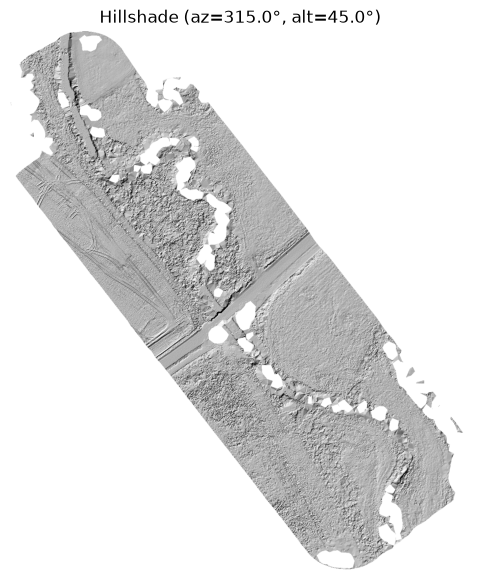

In [45]:
# Compute hillshade

def compute_hillshade(dem, res_x, res_y, azimuth=315, altitude=45, z=1.0):
    dzdy, dzdx = np.gradient(dem * z, res_y, res_x)
    slope = np.arctan(np.sqrt(dzdx**2 + dzdy**2))
    aspect = np.arctan2(-dzdy, dzdx)

    az_rad = np.radians(360.0 - azimuth + 90.0)
    alt_rad = np.radians(altitude)

    hs = (np.sin(alt_rad) * np.cos(slope) +
          np.cos(alt_rad) * np.sin(slope) * np.cos(az_rad - aspect))
    hs = np.clip(hs, 0, 1) * 255.0
    return hs

hillshade = compute_hillshade(dem, res_x, res_y, AZIMUTH_DEG, ALTITUDE_DEG, Z_FACTOR)

# Visualize result
plt.figure(figsize=(9, 7))
plt.imshow(hillshade, cmap="gray")
plt.title(f"Hillshade (az={AZIMUTH_DEG}°, alt={ALTITUDE_DEG}°)")
plt.axis("off")
plt.show()


In [46]:
# Save hillshade to output file
write_raster(OUTPUT_PATH, hillshade, profile)

Saved: output/hillshade_2026.tif
